<a href="https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/sessions/Session06_exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۶: تحلیل اکتشافی داده (EDA)، یک مطالعهٔ موردی کامل

EDA یعنی **گفت‌وگو با داده**: سؤال می‌پرسیم، با نمودار و آمار جواب می‌گیریم و هر جواب سؤال بعدی را می‌سازد. در این جلسه همهٔ ابزارهای جلسه‌های قبل را کنار هم به کار می‌گیریم.

### اهداف این جلسه

- انجام یک EDA کامل و هدفمند، از سؤال تا نتیجه
- بررسی کیفیت داده پیش از تحلیل
- تحلیل تک‌متغیره، دومتغیره و چندمتغیره
- استفاده از تبدیل لگاریتمی برای دادهٔ چوله
- شناخت **متغیر مخدوش‌کننده (Confounder)** و پارادوکس‌هایی که می‌سازد
- نوشتن یافته‌ها به زبان قابل‌فهم برای تصمیم‌گیرنده

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. مسئله و داده

فرض کنید برای یک فروشگاه جواهرات کار می‌کنیم و مدیر می‌پرسد: **«قیمت الماس به چه چیزهایی بستگی دارد؟»**

دادهٔ `diamonds` مشخصات و قیمت حدود ۵۴ هزار الماس را دارد:

| ستون | معنا |
|---|---|
| `price` | قیمت (دلار) |
| `carat` | وزن (هر قیراط ۰٫۲ گرم) |
| `cut` | کیفیت تراش: Fair < Good < Very Good < Premium < Ideal |
| `color` | رنگ: از D (بهترین، بی‌رنگ) تا J (بدترین) |
| `clarity` | شفافیت: I1 (بدترین) < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF (بهترین) |
| `x`, `y`, `z` | ابعاد (میلی‌متر) |
| `depth`, `table` | نسبت‌های هندسی تراش (درصد) |

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Data_Science_Course/main/data/"

df = pd.read_csv(DATA_URL + "diamonds.csv")
print(df.shape)
df.head()

(53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### متغیرهای ترتیبی

`cut`، `color` و `clarity` **ترتیب** دارند. اگر آن‌ها را به نوع `category` با ترتیب مشخص تبدیل کنیم، هم مرتب‌سازی درست انجام می‌شود و هم نمودارها به ترتیب منطقی رسم می‌شوند (نه الفبایی).

</div>

In [2]:
CUT = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
COLOR = ["J", "I", "H", "G", "F", "E", "D"]                     # worst -> best
CLARITY = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]   # worst -> best

df["cut"] = pd.Categorical(df["cut"], categories=CUT, ordered=True)
df["color"] = pd.Categorical(df["color"], categories=COLOR, ordered=True)
df["clarity"] = pd.Categorical(df["clarity"], categories=CLARITY, ordered=True)
df.dtypes

carat       float64
cut        category
color      category
clarity    category
depth       float64
table       float64
price         int64
x           float64
y           float64
z           float64
dtype: object

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. بررسی کیفیت داده

قبل از هر تحلیلی: مقدار گمشده؟ تکرار؟ مقدار غیرممکن؟

</div>

In [3]:
print("missing values :", df.isna().sum().sum())
print("duplicate rows :", df.duplicated().sum())
df.describe().round(2)

missing values : 0
duplicate rows : 146


,carat,depth,table,price,x,y,z
count,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00
mean,0.80,61.75,57.46,3932.80,5.73,5.73,3.54
std,0.47,1.43,2.23,3989.44,1.12,1.14,0.71
min,0.20,43.00,43.00,326.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,950.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,2401.00,5.70,5.71,3.53
75%,1.04,62.50,59.00,5324.25,6.54,6.54,4.04
max,5.01,79.00,95.00,18823.00,10.74,58.90,31.80


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

دو مشکل پیدا شد:

- ۱۴۶ سطر کاملاً تکراری.
- کمینهٔ `x`، `y` و `z` صفر است؛ الماسی با بُعد صفر وجود ندارد. بیشینهٔ `y` (۵۸٫۹ میلی‌متر) و `z` (۳۱٫۸) هم برای الماس‌هایی که بیشترشان زیر ۱۰ میلی‌متر هستند، مشکوک است.

</div>

In [4]:
bad_dims = (df[["x", "y", "z"]] == 0).any(axis=1) | (df["y"] > 20) | (df["z"] > 20)
df.loc[bad_dims, ["carat", "price", "x", "y", "z"]].head(8)

,carat,price,x,y,z
2207,1.00,3142,6.55,6.48,0.0
2314,1.01,3167,6.66,6.60,0.0
4791,1.10,3696,6.50,6.47,0.0
5471,1.01,3837,6.50,6.47,0.0
10167,1.50,4731,7.15,7.04,0.0
11182,1.07,4954,0.00,6.62,0.0
11963,1.00,5139,0.00,0.00,0.0
13601,1.15,5564,6.88,6.83,0.0


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

الماس ۲ قیراطی با `y=58.9` میلی‌متر ممکن نیست؛ این‌ها خطای ورود داده‌اند. تعدادشان ناچیز است (حدود ۰٫۰۴٪)، پس حذفشان می‌کنیم.

</div>

In [5]:
df = df.drop_duplicates()
df = df[~((df[["x", "y", "z"]] == 0).any(axis=1) | (df["y"] > 20) | (df["z"] > 20))].reset_index(drop=True)
print(df.shape)

(53772, 10)


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. تحلیل تک‌متغیره: متغیر هدف

</div>

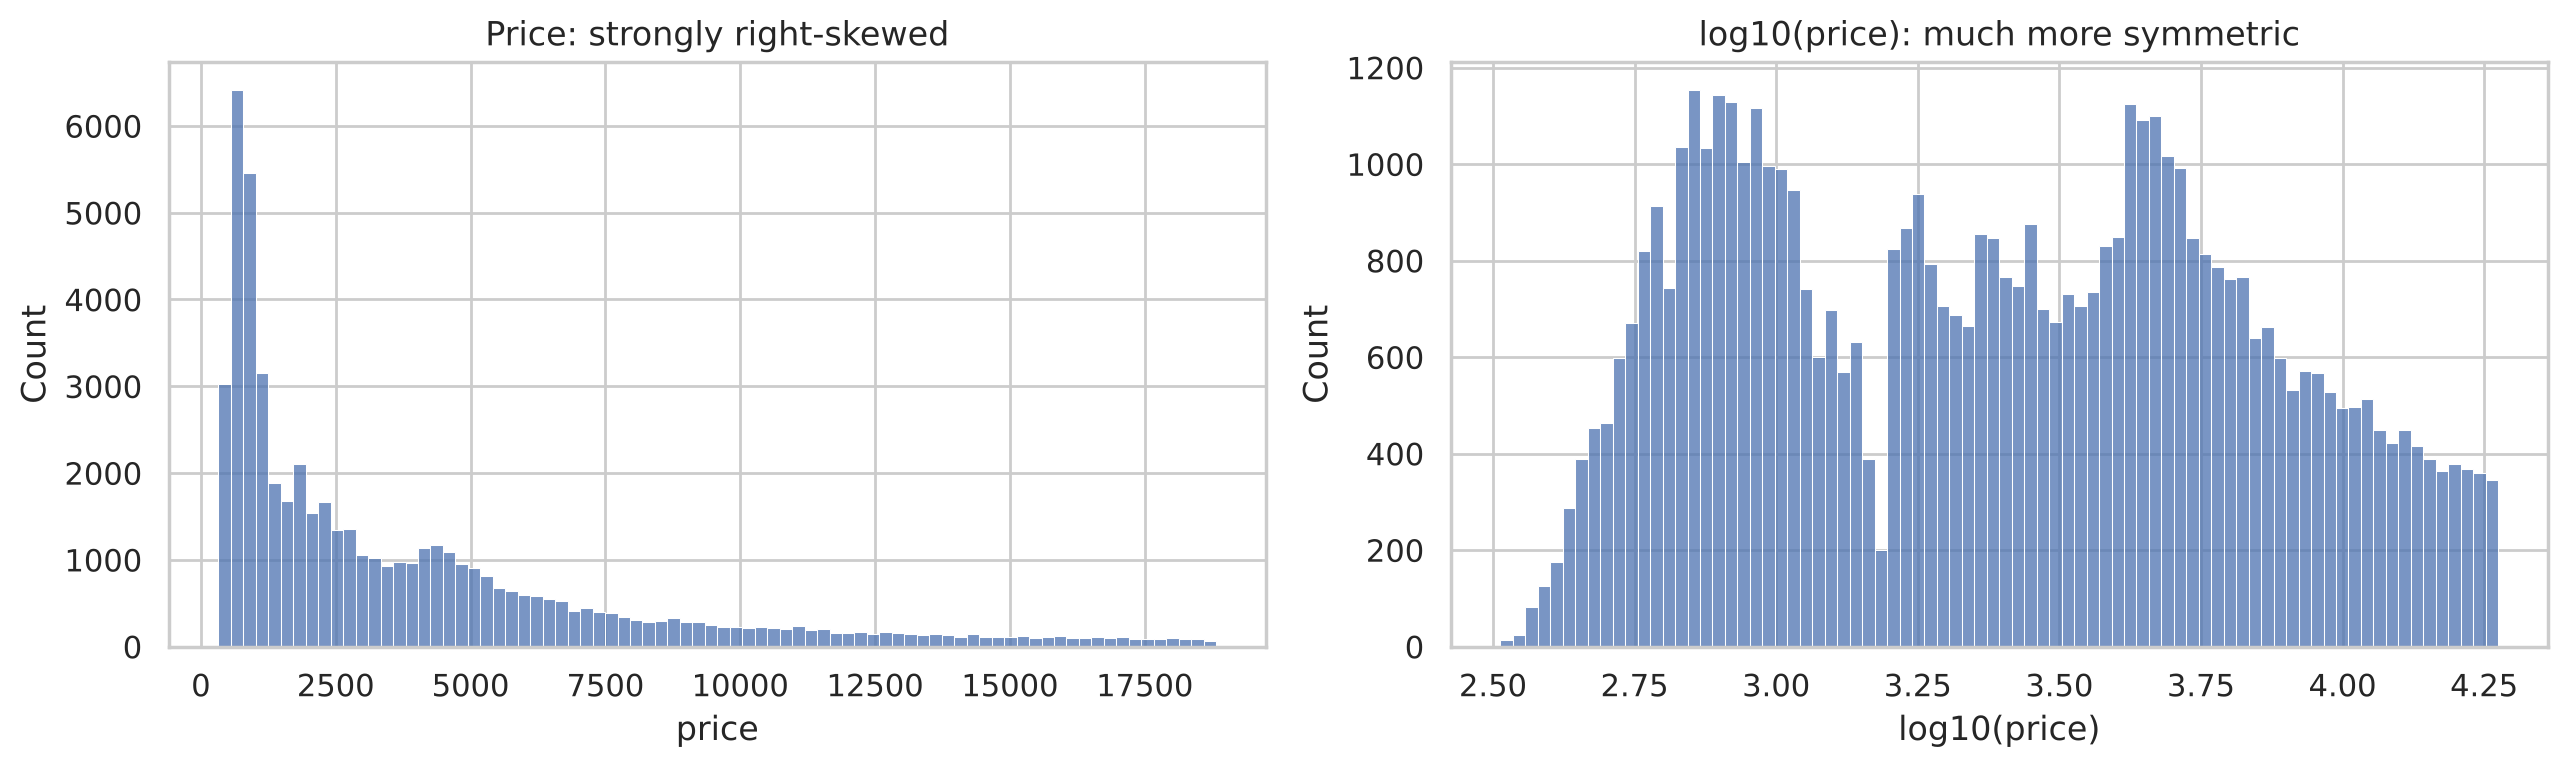

mean = 3,931   median = 2,401   skew = 1.62


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["price"], bins=80, ax=axes[0])
axes[0].set_title("Price: strongly right-skewed")
sns.histplot(np.log10(df["price"]), bins=80, ax=axes[1])
axes[1].set_title("log10(price): much more symmetric")
axes[1].set_xlabel("log10(price)")
plt.tight_layout()
plt.show()

print(f"mean = {df['price'].mean():,.0f}   median = {df['price'].median():,.0f}   skew = {df['price'].skew():.2f}")

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- توزیع قیمت **چوله به راست** است: تعداد زیادی الماس ارزان و تعداد کمی بسیار گران. به همین دلیل میانگین (حدود ۳۹۰۰) خیلی بیشتر از میانه (حدود ۲۴۰۰) است. برای دادهٔ چوله، **میانه** معرف بهتری است.
- بعد از لگاریتم، توزیع متقارن‌تر شده است. قیمت‌ها معمولاً **ضربی** تغییر می‌کنند (مثلاً «۲۰٪ گران‌تر»)، و لگاریتم تغییر ضربی را به تغییر جمعی تبدیل می‌کند.

</div>

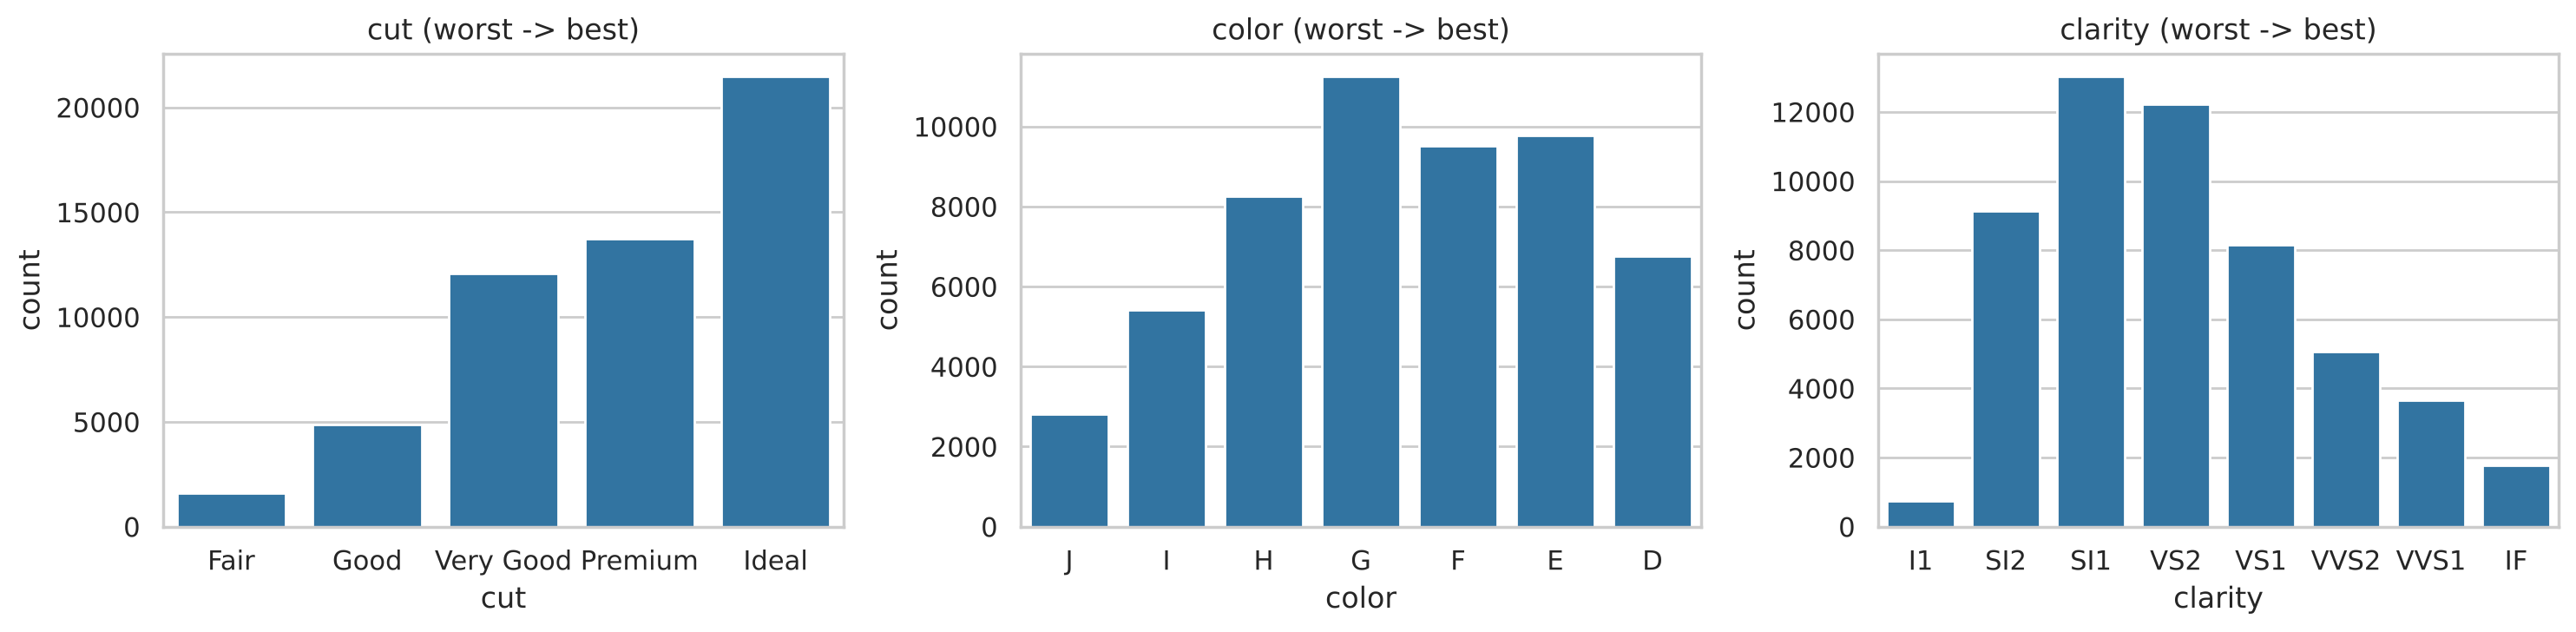

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["cut", "color", "clarity"]):
    sns.countplot(data=df, x=col, ax=ax, color="tab:blue")
    ax.set_title(f"{col} (worst -> best)")
plt.tight_layout()
plt.show()

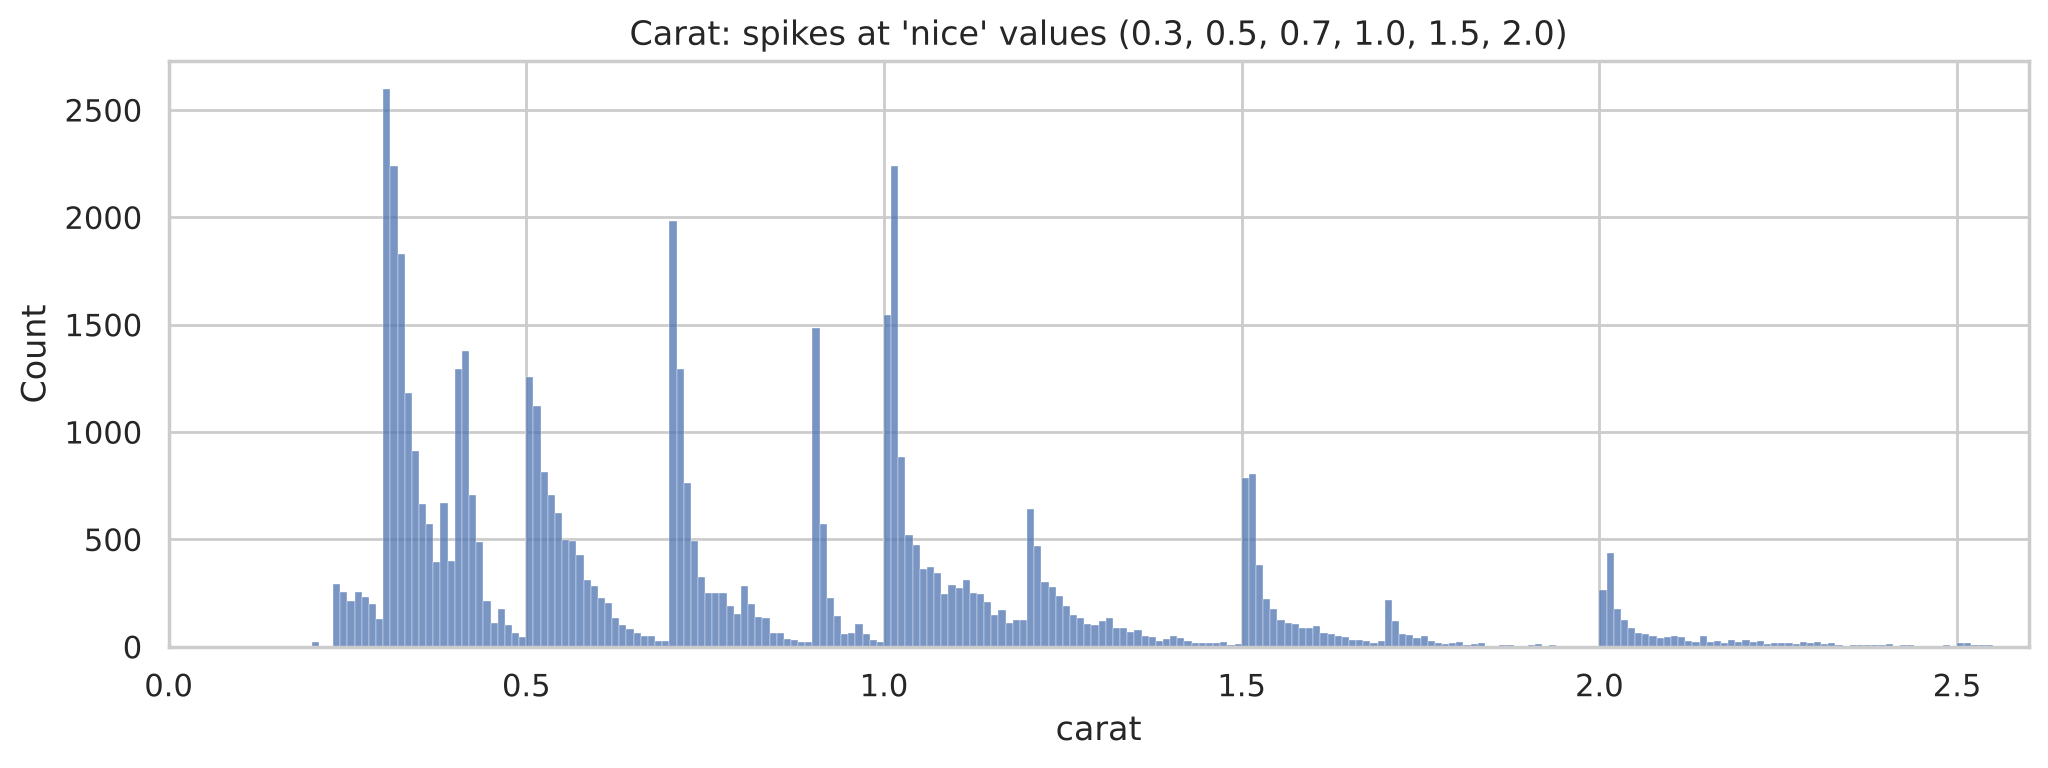

In [8]:
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.histplot(df["carat"], binwidth=0.01, ax=ax)
ax.set_xlim(0, 2.6)
ax.set_title("Carat: spikes at 'nice' values (0.3, 0.5, 0.7, 1.0, 1.5, 2.0)")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

یک الگوی جالب: در وزن‌های «رُند» مثل ۱٫۰ و ۱٫۵ قیراط جهش‌های تیز وجود دارد و درست قبل از آن‌ها تعداد کم است. احتمالاً تراش‌کارها ترجیح می‌دهند الماس را کمی سنگین‌تر از ۱ قیراط تراش دهند تا بتوانند آن را با برچسب «۱ قیراط» بفروشند. EDA خوب این جزئیات انسانی را هم آشکار می‌کند.

## ۴. تحلیل دومتغیره: کیفیت تراش و قیمت

انتظار طبیعی: هرچه تراش بهتر، قیمت بیشتر. بیایید بررسی کنیم.

</div>

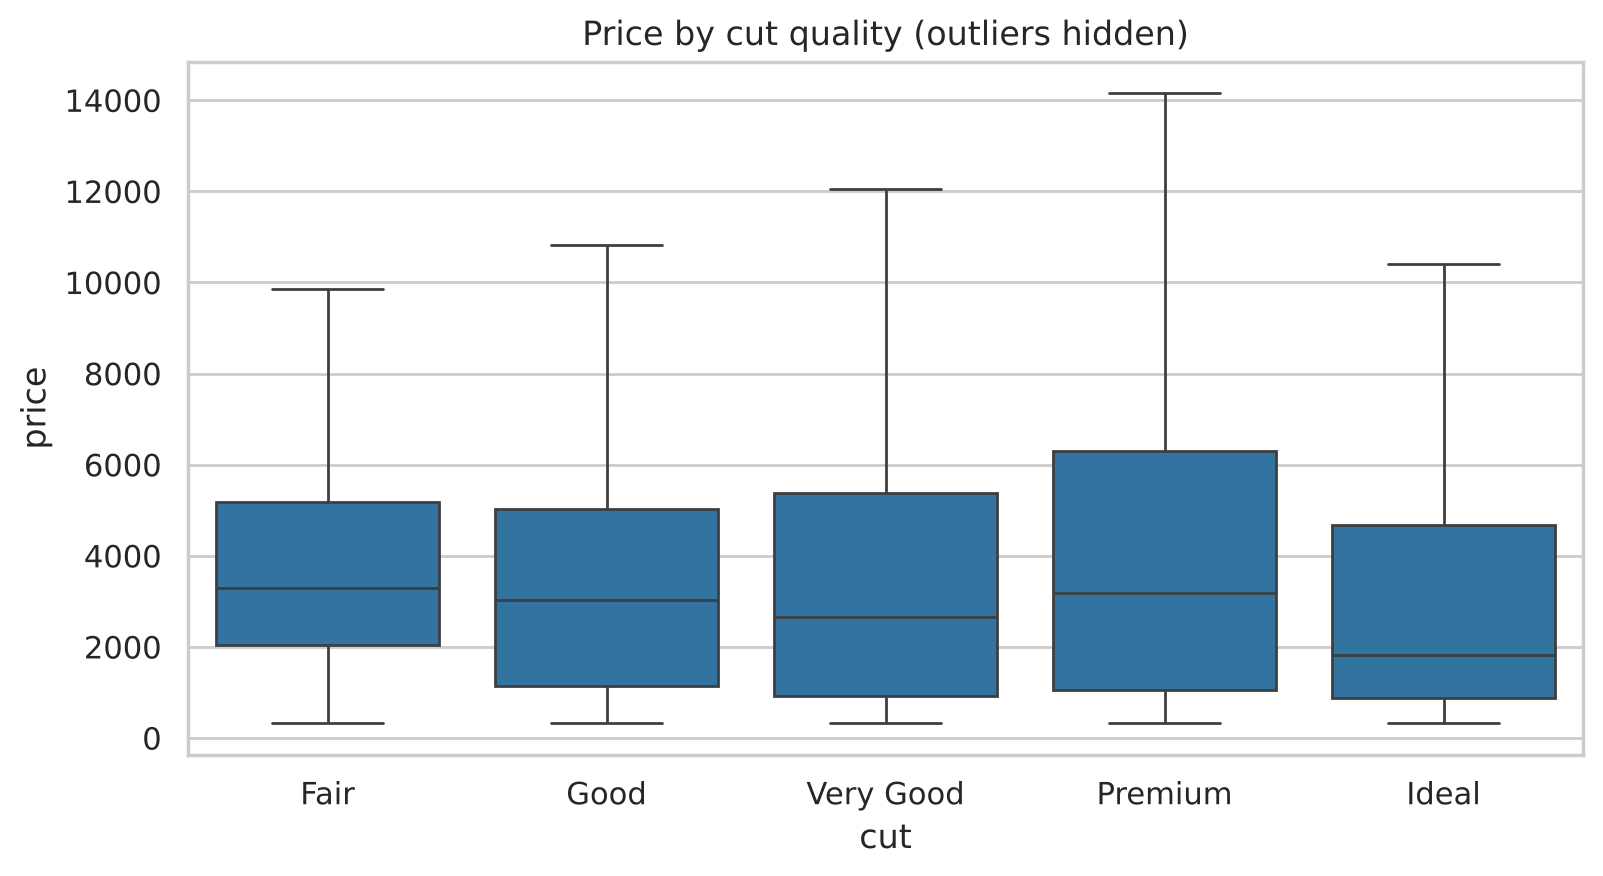

cut
Fair         3282.0
Good         3038.0
Very Good    2647.0
Premium      3177.5
Ideal        1813.0
Name: price, dtype: float64

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df, x="cut", y="price", ax=ax, showfliers=False, color="tab:blue")
ax.set_title("Price by cut quality (outliers hidden)")
plt.show()

df.groupby("cut", observed=True)["price"].median()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**عجیب است!** الماس‌های با تراش Ideal (بهترین) کمترین میانهٔ قیمت را دارند و Fair (بدترین) جزو گران‌ترین‌هاست. همین الگو برای رنگ هم دیده می‌شود:

</div>

In [10]:
df.groupby("color", observed=True)["price"].median()

color
J    4234.5
I    3720.0
H    3447.0
G    2242.0
F    2345.0
E    1740.0
D    1842.0
Name: price, dtype: float64

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

رنگ J (بدترین) گران‌ترین است و D (بهترین) ارزان‌ترین! آیا مشتری‌ها کیفیت بدتر را ترجیح می‌دهند؟ قبل از گزارش این «کشف» به مدیر، باید به متغیرهای دیگر نگاه کنیم.

## ۵. مهم‌ترین متغیر: وزن

</div>

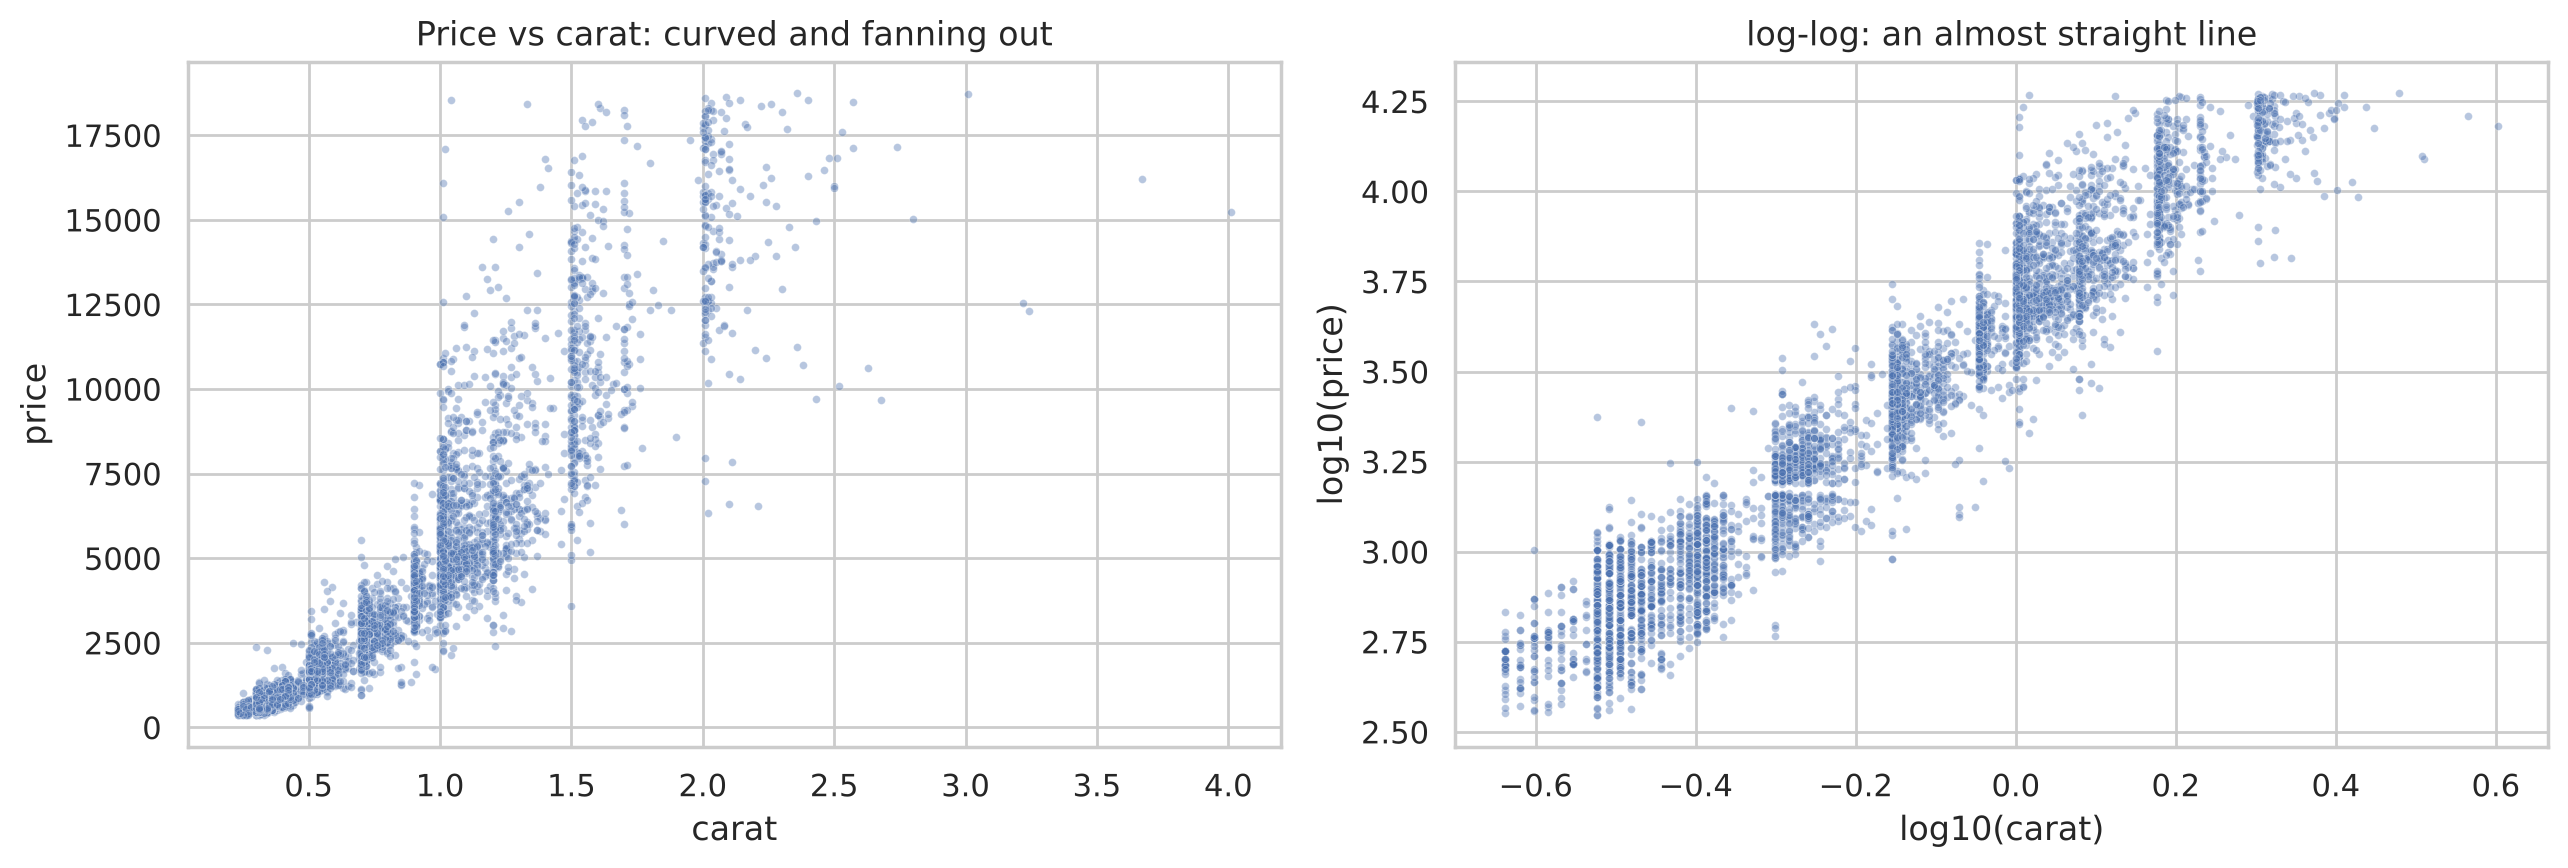

corr(carat, price)          : 0.922
corr(log carat, log price)  : 0.966


In [11]:
sample = df.sample(5000, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=sample, x="carat", y="price", s=8, alpha=0.4, ax=axes[0])
axes[0].set_title("Price vs carat: curved and fanning out")
sns.scatterplot(x=np.log10(sample["carat"]), y=np.log10(sample["price"]), s=8, alpha=0.4, ax=axes[1])
axes[1].set_title("log-log: an almost straight line")
axes[1].set_xlabel("log10(carat)")
axes[1].set_ylabel("log10(price)")
plt.tight_layout()
plt.show()

print("corr(carat, price)          :", round(df["carat"].corr(df["price"]), 3))
print("corr(log carat, log price)  :", round(np.log(df["carat"]).corr(np.log(df["price"])), 3))

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

وزن، قوی‌ترین عامل قیمت است. در مقیاس لگاریتمی رابطه تقریباً خطی است. (برای رسم پراکندگی از یک نمونهٔ ۵۰۰۰تایی استفاده کردیم؛ رسم ۵۴ هزار نقطه فقط یک لکهٔ سیاه می‌ساخت.)

حالا ببینیم وزن در گروه‌های مختلف تراش چطور توزیع شده است:

</div>

In [12]:
df.groupby("cut", observed=True)["carat"].median()

cut
Fair         1.00
Good         0.82
Very Good    0.71
Premium      0.85
Ideal        0.54
Name: carat, dtype: float64

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۶. حل معما: متغیر مخدوش‌کننده

الماس‌های Ideal به‌طور میانه سبک‌ترند (۰٫۵۴ قیراط در برابر ۱ قیراط برای Fair). یعنی:

- وزن روی قیمت اثر مستقیم و بزرگ دارد.
- وزن با کیفیت تراش هم ارتباط دارد (سنگ‌های بزرگ را معمولاً طوری تراش می‌دهند که وزن بیشتری حفظ شود، حتی به قیمت تراش ضعیف‌تر).

به چنین متغیری که هم روی «علت» ظاهری و هم روی «نتیجه» اثر دارد، **متغیر مخدوش‌کننده (Confounder)** می‌گویند. برای دیدن اثر واقعی تراش باید وزن را **ثابت نگه داریم**. ساده‌ترین روش: فقط الماس‌های با وزن تقریباً یکسان را مقایسه کنیم.

</div>

In [13]:
one_carat = df[df["carat"].between(0.9, 1.1)]
print(len(one_carat), "diamonds between 0.9 and 1.1 carat")
pd.DataFrame({
    "all diamonds": df.groupby("cut", observed=True)["price"].median(),
    "0.9-1.1 carat only": one_carat.groupby("cut", observed=True)["price"].median(),
})

10306 diamonds between 0.9 and 1.1 carat


,all diamonds,0.9-1.1 carat only
cut,,
Fair,3282.0,3733.0
Good,3038.0,4310.5
Very Good,2647.0,4690.0
Premium,3177.5,4672.0
Ideal,1813.0,5222.0


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با ثابت نگه داشتن وزن، ترتیب کاملاً برعکس شد: حالا Ideal گران‌ترین است، همان‌طور که انتظار داشتیم. یک روش جامع‌تر، رسم رابطهٔ وزن و قیمت برای **هر** گروه است:

</div>

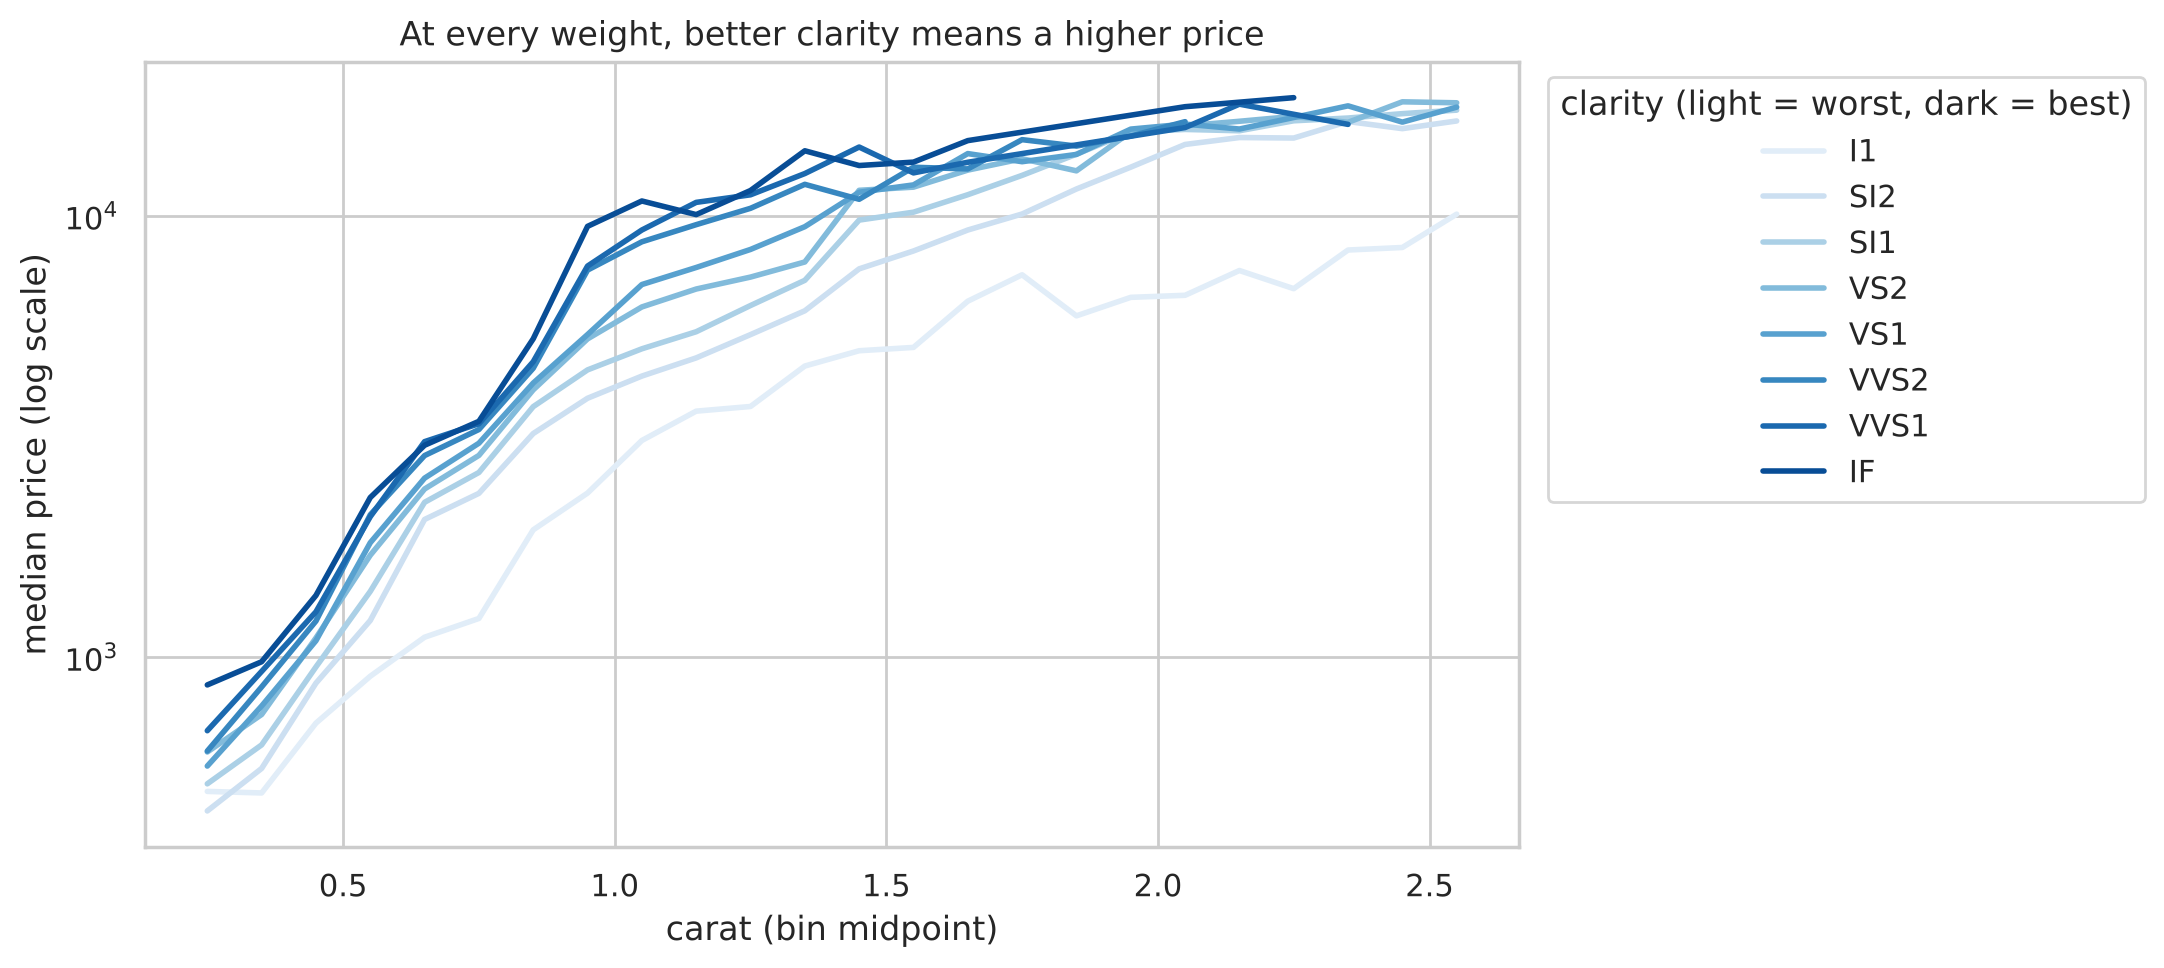

In [14]:
bins = pd.cut(df["carat"], bins=np.arange(0.2, 2.61, 0.1))
by_bin = (df.groupby([bins, "clarity"], observed=True)["price"].median()
            .reset_index())
by_bin["carat_mid"] = by_bin["carat"].apply(lambda iv: iv.mid).astype(float)

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=by_bin, x="carat_mid", y="price", hue="clarity", palette="Blues", ax=ax, linewidth=2)
ax.set_yscale("log")
ax.set_xlabel("carat (bin midpoint)")
ax.set_ylabel("median price (log scale)")
ax.set_title("At every weight, better clarity means a higher price")
ax.legend(title="clarity (light = worst, dark = best)", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در هر وزن مشخص، شفافیت بهتر (رنگ تیره‌تر) قیمت بیشتری دارد. چون `clarity` یک متغیر **ترتیبی** است، از یک طیف تک‌رنگ (روشن به تیره) استفاده کردیم تا ترتیب در خود رنگ دیده شود.

### قیمت به ازای هر قیراط

راه دیگر حذف اثر وزن، ساختن یک ویژگی **نسبی** است:

</div>

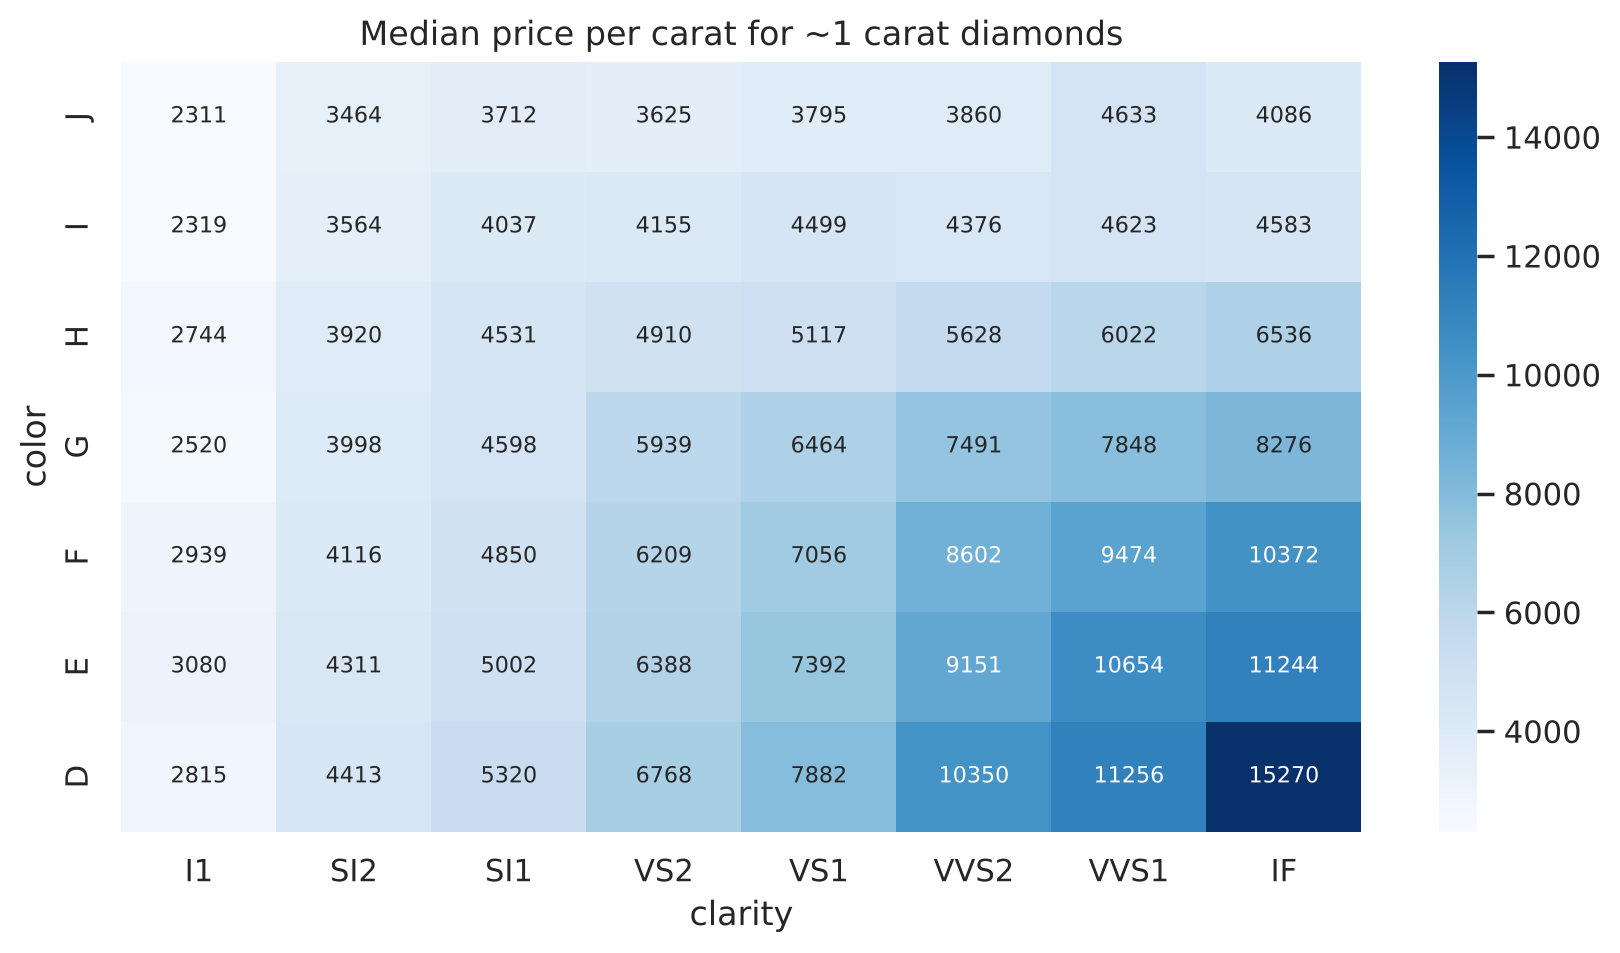

In [15]:
df["price_per_carat"] = df["price"] / df["carat"]
pivot = df[df["carat"].between(0.9, 1.1)].pivot_table(
    index="color", columns="clarity", values="price_per_carat", aggfunc="median", observed=True)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(pivot, cmap="Blues", annot=True, fmt=".0f", annot_kws={"size": 8}, ax=ax)
ax.set_title("Median price per carat for ~1 carat diamonds")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

گوشهٔ پایین‌راست (بهترین رنگ و بهترین شفافیت) بیشترین قیمت به ازای هر قیراط را دارد و گوشهٔ بالاچپ کمترین. حالا همه‌چیز با انتظار ما سازگار است.

## ۷. همبستگی بین ویژگی‌های عددی

</div>

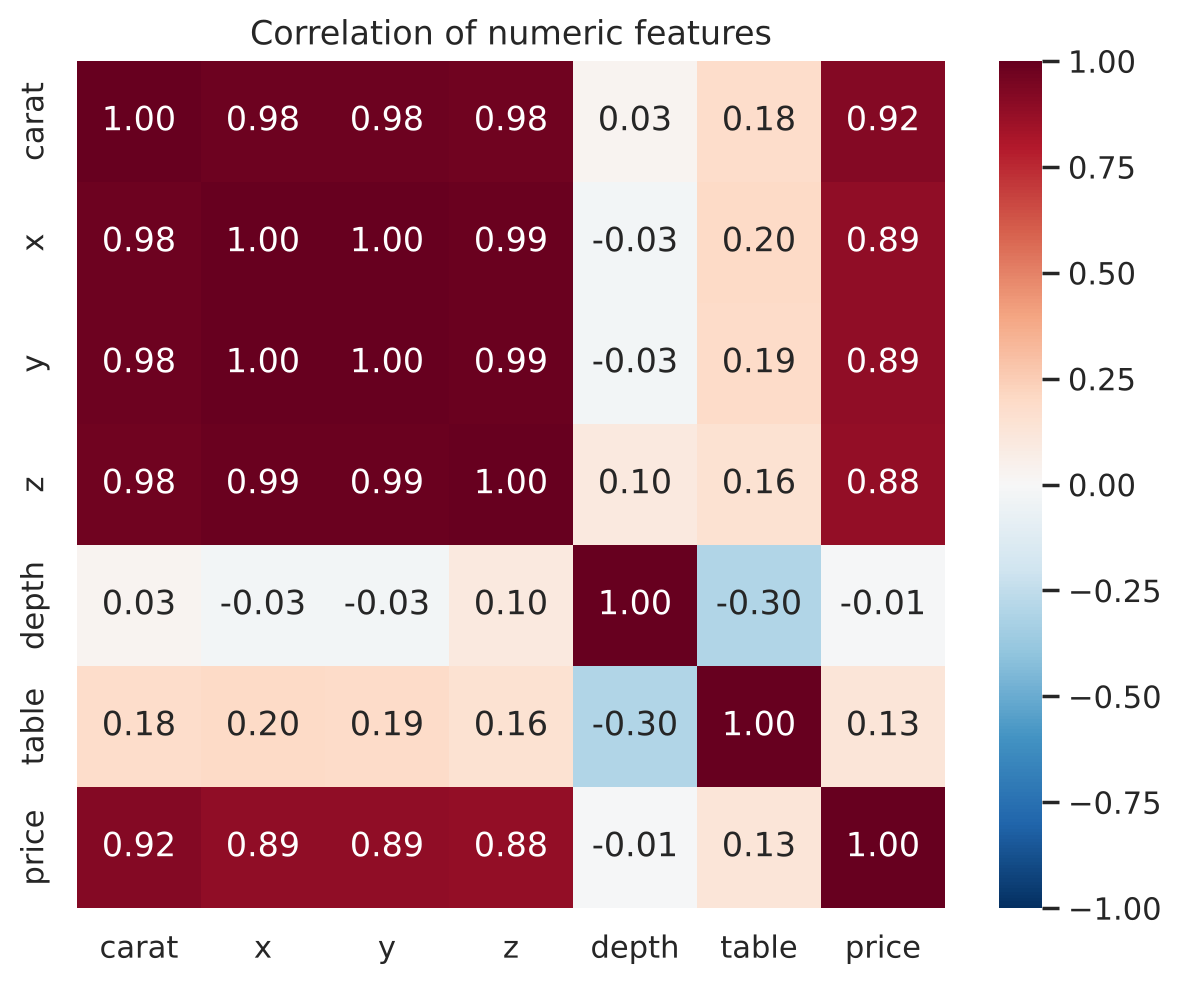

In [16]:
num = df[["carat", "x", "y", "z", "depth", "table", "price"]]
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Correlation of numeric features")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

`carat`، `x`، `y` و `z` تقریباً همبستگی کامل دارند؛ طبیعی است، چون وزن از حجم به دست می‌آید. این ستون‌ها اطلاعات **تکراری** دارند (هم‌خطی). در ترم بعد می‌بینیم که این موضوع در مدل‌های خطی مشکل‌ساز است. `depth` و `table` تقریباً هیچ همبستگی خطی با قیمت ندارند.

## ۸. گزارش یافته‌ها

یافته‌های EDA باید به زبان تصمیم‌گیرنده نوشته شوند، نه به زبان کد:

1. **وزن، عامل اصلی قیمت است.** رابطه غیرخطی است: با دو برابر شدن وزن، قیمت تقریباً سه برابر می‌شود.
2. **در وزن یکسان، کیفیت بهتر (تراش، رنگ، شفافیت) قیمت بیشتری دارد.**
3. **مقایسهٔ سادهٔ میانگین‌ها گمراه‌کننده است.** الماس‌های با کیفیت بالا در این داده به‌طور میانگین کوچک‌ترند و همین باعث می‌شود ارزان‌تر به نظر برسند.
4. **اثر روانی وزن‌های رُند:** تعداد الماس‌های درست بالای ۱٫۰ و ۱٫۵ قیراط بسیار بیشتر از درست زیر آن‌هاست.
5. **کیفیت داده:** ۱۴۶ سطر تکراری و حدود ۲۰ سطر با ابعاد غیرممکن حذف شدند.

## جمع‌بندی: چک‌لیست EDA

1. سؤال را روشن کنید.
2. کیفیت داده را بسنجید (گمشده، تکرار، غیرممکن).
3. متغیر هدف را بشناسید (توزیع، چولگی، تبدیل).
4. هر ویژگی را جداگانه ببینید.
5. رابطهٔ هر ویژگی با هدف را ببینید.
6. **قبل از نتیجه‌گیری، به دنبال متغیرهای مخدوش‌کننده بگردید.**
7. یافته‌ها را به زبان ساده و همراه با نمودار گزارش کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. معمای «رنگ» را حل کنید: نشان دهید که با ثابت نگه داشتن وزن (مثلاً ۰٫۹ تا ۱٫۱ قیراط)، رنگ D گران‌تر از J است.

۲. یک ستون `volume = x * y * z` بسازید و رابطهٔ آن را با `carat` رسم کنید. آیا دادهٔ مشکوکی می‌بینید؟

۳. با `sns.displot(..., col="cut")` توزیع `log10(price)` را برای هر گروه تراش رسم کنید.

۴. اختلاف قیمت میانهٔ الماس‌های ۰٫۹۵ تا ۰٫۹۹ قیراط و ۱٫۰۰ تا ۱٫۰۴ قیراط چقدر است؟ این اختلاف چه چیزی دربارهٔ بازار می‌گوید؟

۵. یک EDA کوتاه روی دادهٔ `tips` انجام دهید و سه یافتهٔ اصلی را به زبان ساده بنویسید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** معمای «رنگ» را حل کنید: نشان دهید که با ثابت نگه داشتن وزن (مثلاً ۰٫۹ تا ۱٫۱ قیراط)، رنگ D گران‌تر از J است.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** یک ستون `volume = x * y * z` بسازید و رابطهٔ آن را با `carat` رسم کنید. آیا دادهٔ مشکوکی می‌بینید؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** با `sns.displot(..., col="cut")` توزیع `log10(price)` را برای هر گروه تراش رسم کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** اختلاف قیمت میانهٔ الماس‌های ۰٫۹۵ تا ۰٫۹۹ قیراط و ۱٫۰۰ تا ۱٫۰۴ قیراط چقدر است؟ این اختلاف چه چیزی دربارهٔ بازار می‌گوید؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** یک EDA کوتاه روی دادهٔ `tips` انجام دهید و سه یافتهٔ اصلی را به زبان ساده بنویسید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
